In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    "data",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=42
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    "data",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=42
)

Found 7023 files belonging to 4 classes.
Using 5619 files for training.
Found 7023 files belonging to 4 classes.
Using 1404 files for validation.


In [3]:
class_names = train_data.class_names
print("Classes :", class_names)

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


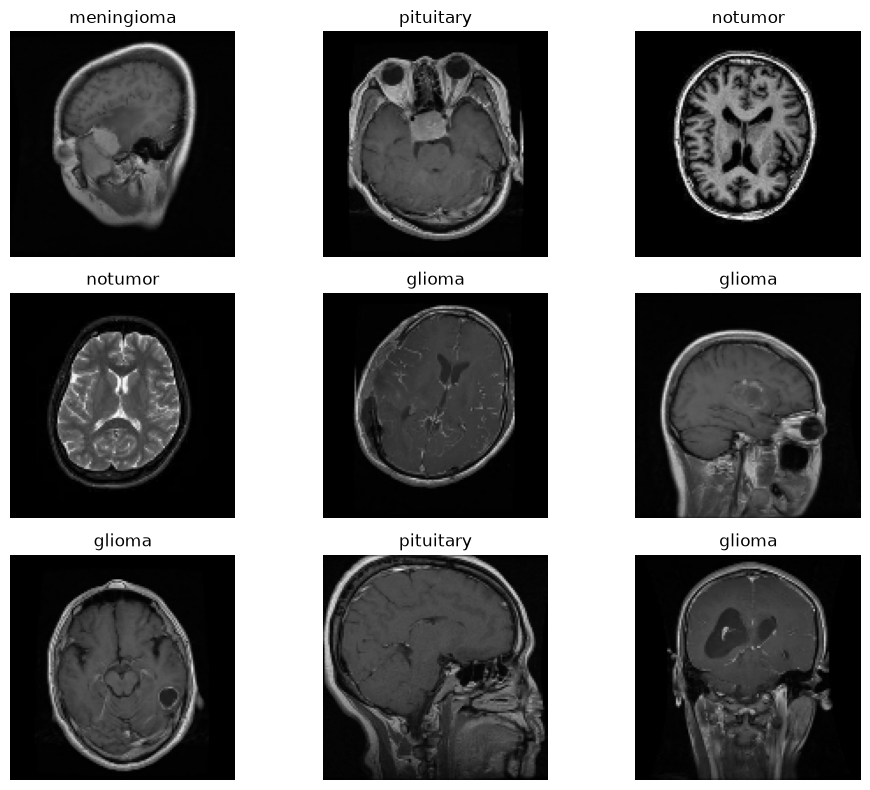

In [4]:
plt.figure(figsize=(10, 8))

for images, labels in train_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
for image_batch, labels_batch in train_data:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 128, 128, 3)
(32,)


L' image_batch est un tenseur de la forme (32, 180, 180, 3) . Il s'agit d'un lot de 32 images de forme 180x180x3 (la dernière dimension fait référence aux canaux de couleur RVB). Le label_batch est un tenseur de la forme (32,) , ce sont des labels correspondants aux 32 images.

In [6]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
normalized_train_data = train_data.map(lambda x, y: (normalization_layer(x), y))

In [7]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,612 (7.05 MB)

 Trainable params: 1,848,612 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    normalized_train_data,
    validation_data=validation_data.map(lambda x, y: (normalization_layer(x), y)),
    epochs=10,
    batch_size=BATCH_SIZE,
)

Epoch 1/10


c:\Users\youco\Desktop\live-coding-tensorflow-keras\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


176/176 ━━━━━━━━━━━━━━━━━━━━ 14s 77ms/step - accuracy: 0.7218 - loss: 0.6867 - val_accuracy: 0.8191 - val_loss: 0.4650
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.8710 - loss: 0.3296 - val_accuracy: 0.8896 - val_loss: 0.3162
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.9279 - loss: 0.1991 - val_accuracy: 0.8761 - val_loss: 0.3361
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.9557 - loss: 0.1262 - val_accuracy: 0.9174 - val_loss: 0.2428
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9753 - loss: 0.0731 - val_accuracy: 0.9316 - val_loss: 0.2026
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 14s 81ms/step - accuracy: 0.9849 - loss: 0.0520 - val_accuracy: 0.9402 - val_loss: 0.2182
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 76ms/step - accuracy: 0.9925 - loss: 0.0297 - val_accuracy: 0.9302 - val_loss: 0.2592
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9851 - loss: 0.0501 - val_accurac

In [ ]:
test_loss, test_accuracy = model.evaluate(validation_data.map(lambda x, y: (normalization_layer(x), y)))

print("Test loss :", test_loss)
print("Test accuracy :", test_accuracy)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9530 - loss: 0.2130
Test loss : 0.21296587586402893
Test accuracy : 0.9529914259910583


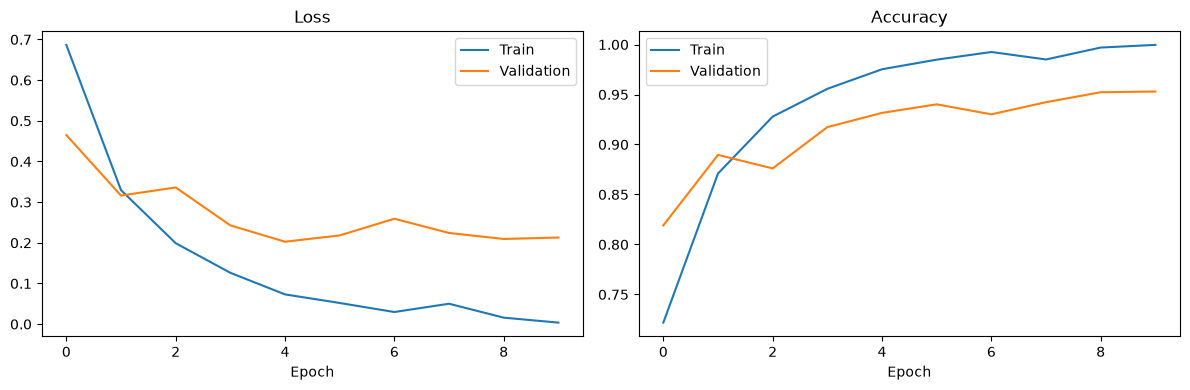

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

**Interprétation :**<br>
Overfitting : la loss d'entraînement diminue, mais celle de validation augmente.

array([0., 1., 0., 0.], dtype=float32)

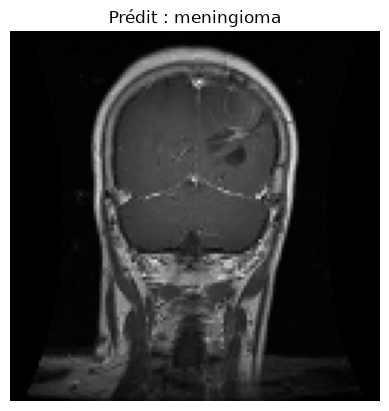

Classe prédite : meningioma
Classe réelle : glioma


In [ ]:
for images, labels in validation_data.take(1):
    image = images[0:1]

    probabilities = model.predict(image, verbose=0)[0]
    predicted_class = np.argmax(probabilities)

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Prédit : {class_names[predicted_class]}")
    plt.axis("off")
    plt.show()

    print("Classe prédite :", class_names[predicted_class])
    print("Classe réelle :", class_names[int(labels[0])])